In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.image as mpimg
from matplotlib.lines import Line2D
from highlight_text import ax_text, fig_text
from drawarrow import ax_arrow, fig_arrow
from pyfonts import load_google_font

from scipy.interpolate import PchipInterpolator

import os

In [2]:
# cleaned file
f_path = os.path.join(
    "..", "data", "clean",
    "launches_clean_plotting.csv"
)

data = pd.read_csv(f_path)

data.tail(1)

,Date,total_payloads,Overall,USA,Europe,Asia,Other
37,2025-12-24,1,434,233,139,41,21


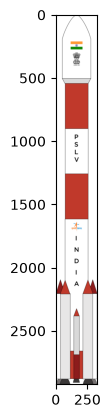

In [3]:
# load PSLV image
rocket_img = mpimg.imread(
    os.path.join(
        "..", "data", "image",
        "pslv.png"
    )
)

plt.imshow(rocket_img)

In [4]:
df = data.copy()

region_cols = ["USA", "Europe", "Asia", "Other"]

df_yearly = (
    df.assign(Date=pd.to_datetime(df["Date"]))
    .sort_values("Date")
    .set_index("Date")
    .resample("YE")[region_cols]
    .last()
    .ffill()
)

df_yearly["Overall"] = df_yearly[region_cols].sum(axis=1)

df_yearly["Year"] = df_yearly.index.year

df_yearly = df_yearly.reset_index(drop=True)

In [5]:
# df_yearly.to_csv(
#     os.path.join(
#     "..", "data", "clean",
#     "launches_clean_yearly_region.csv"
# ),
# index=False
# )

In [6]:
# regions to show
region_cols = ["USA", "Europe", "Asia", "Other"]

# dataset for plotting
df_plot = df_yearly.sort_values("Year").copy()

# actual non-smoothed data
x = df_plot["Year"].to_numpy(dtype=float)

y_usa = df_plot["USA"].to_numpy(dtype=float)
y_eu = df_plot["Europe"].to_numpy(dtype=float)
y_asia = df_plot["Asia"].to_numpy(dtype=float)
y_other = df_plot["Other"].to_numpy(dtype=float)

# smoothed data
x_sm = np.linspace(
    x.min(),
    x.max(),
    500
)

y_usa_sm = PchipInterpolator(x, y_usa)(x_sm)
y_eu_sm = PchipInterpolator(x, y_eu)(x_sm)
y_asia_sm = PchipInterpolator(x, y_asia)(x_sm)
y_other_sm = PchipInterpolator(x, y_other)(x_sm)

In [7]:
# milestones to annotate
y_min_milestone = 2010
df_mile = df_plot[df_plot["Year"]>=y_min_milestone]

milestone_years = list(range(y_min_milestone, 2026, 5))

milestone_totals = [
    df_mile[df_mile["Year"]==y]["Overall"].values[0] for y in milestone_years
]

In [39]:
# colors
# 00496FFF, #0F85A0FF, #EDD746FF, #ED8B00FF, #DD4124FF
#FCDD23FF, #F8B100FF, #CA697CFF, #AB74CFFF, #48439BFF, #03045e
"#042a2b","#5eb1bf","#cdedf6","#ef7b45","#d84727"
#4B6892FF, #F9E583FF, #FED43FFF, #F6BD28FF, #BE4C46FF
#2E0F16FF, #A32A2FFF, #EB9352FF, #F8E3DBFF, #91837DFF, #37947EFF
#4A3A3BFF, #984136FF, #C26A7AFF, #ECC0A1FF, #F0F0E4FF
#242424FF, #37253DFF, #852851FF, #E10131FF, #F6F4F5FF
#010101FF, #BA0C2FFF, #E03C31FF, #FFCD00FF


color_palette = {
    "background": "#FFF4E5",
    "text": "#25333B",
    "grid": "#D4C9BA",
    "usa": "#31576A",
    "europe": "#B34E4B",
    "asia": "#DB8950",
    "other": "#E8C96C",
    "pslv": "#7363A5",
    "other_vehicles": "#DDD4C9",
    "accent":"#D9603B"
}

region_colors = [
    color_palette["usa"],   # USA
    color_palette["europe"],   # Europe
    color_palette["asia"],   # Asia
    color_palette["other"]    # Other
]
# regions to plot
region_cols = ["USA", "Europe", "Asia", "Other"]

bold = load_google_font("Fira Sans", weight=500)
regular = load_google_font("Fira Sans", weight=300)
thin = load_google_font("Fira Sans", weight=100)
thin_italic = load_google_font("Fira Sans", italic=True, weight=200)




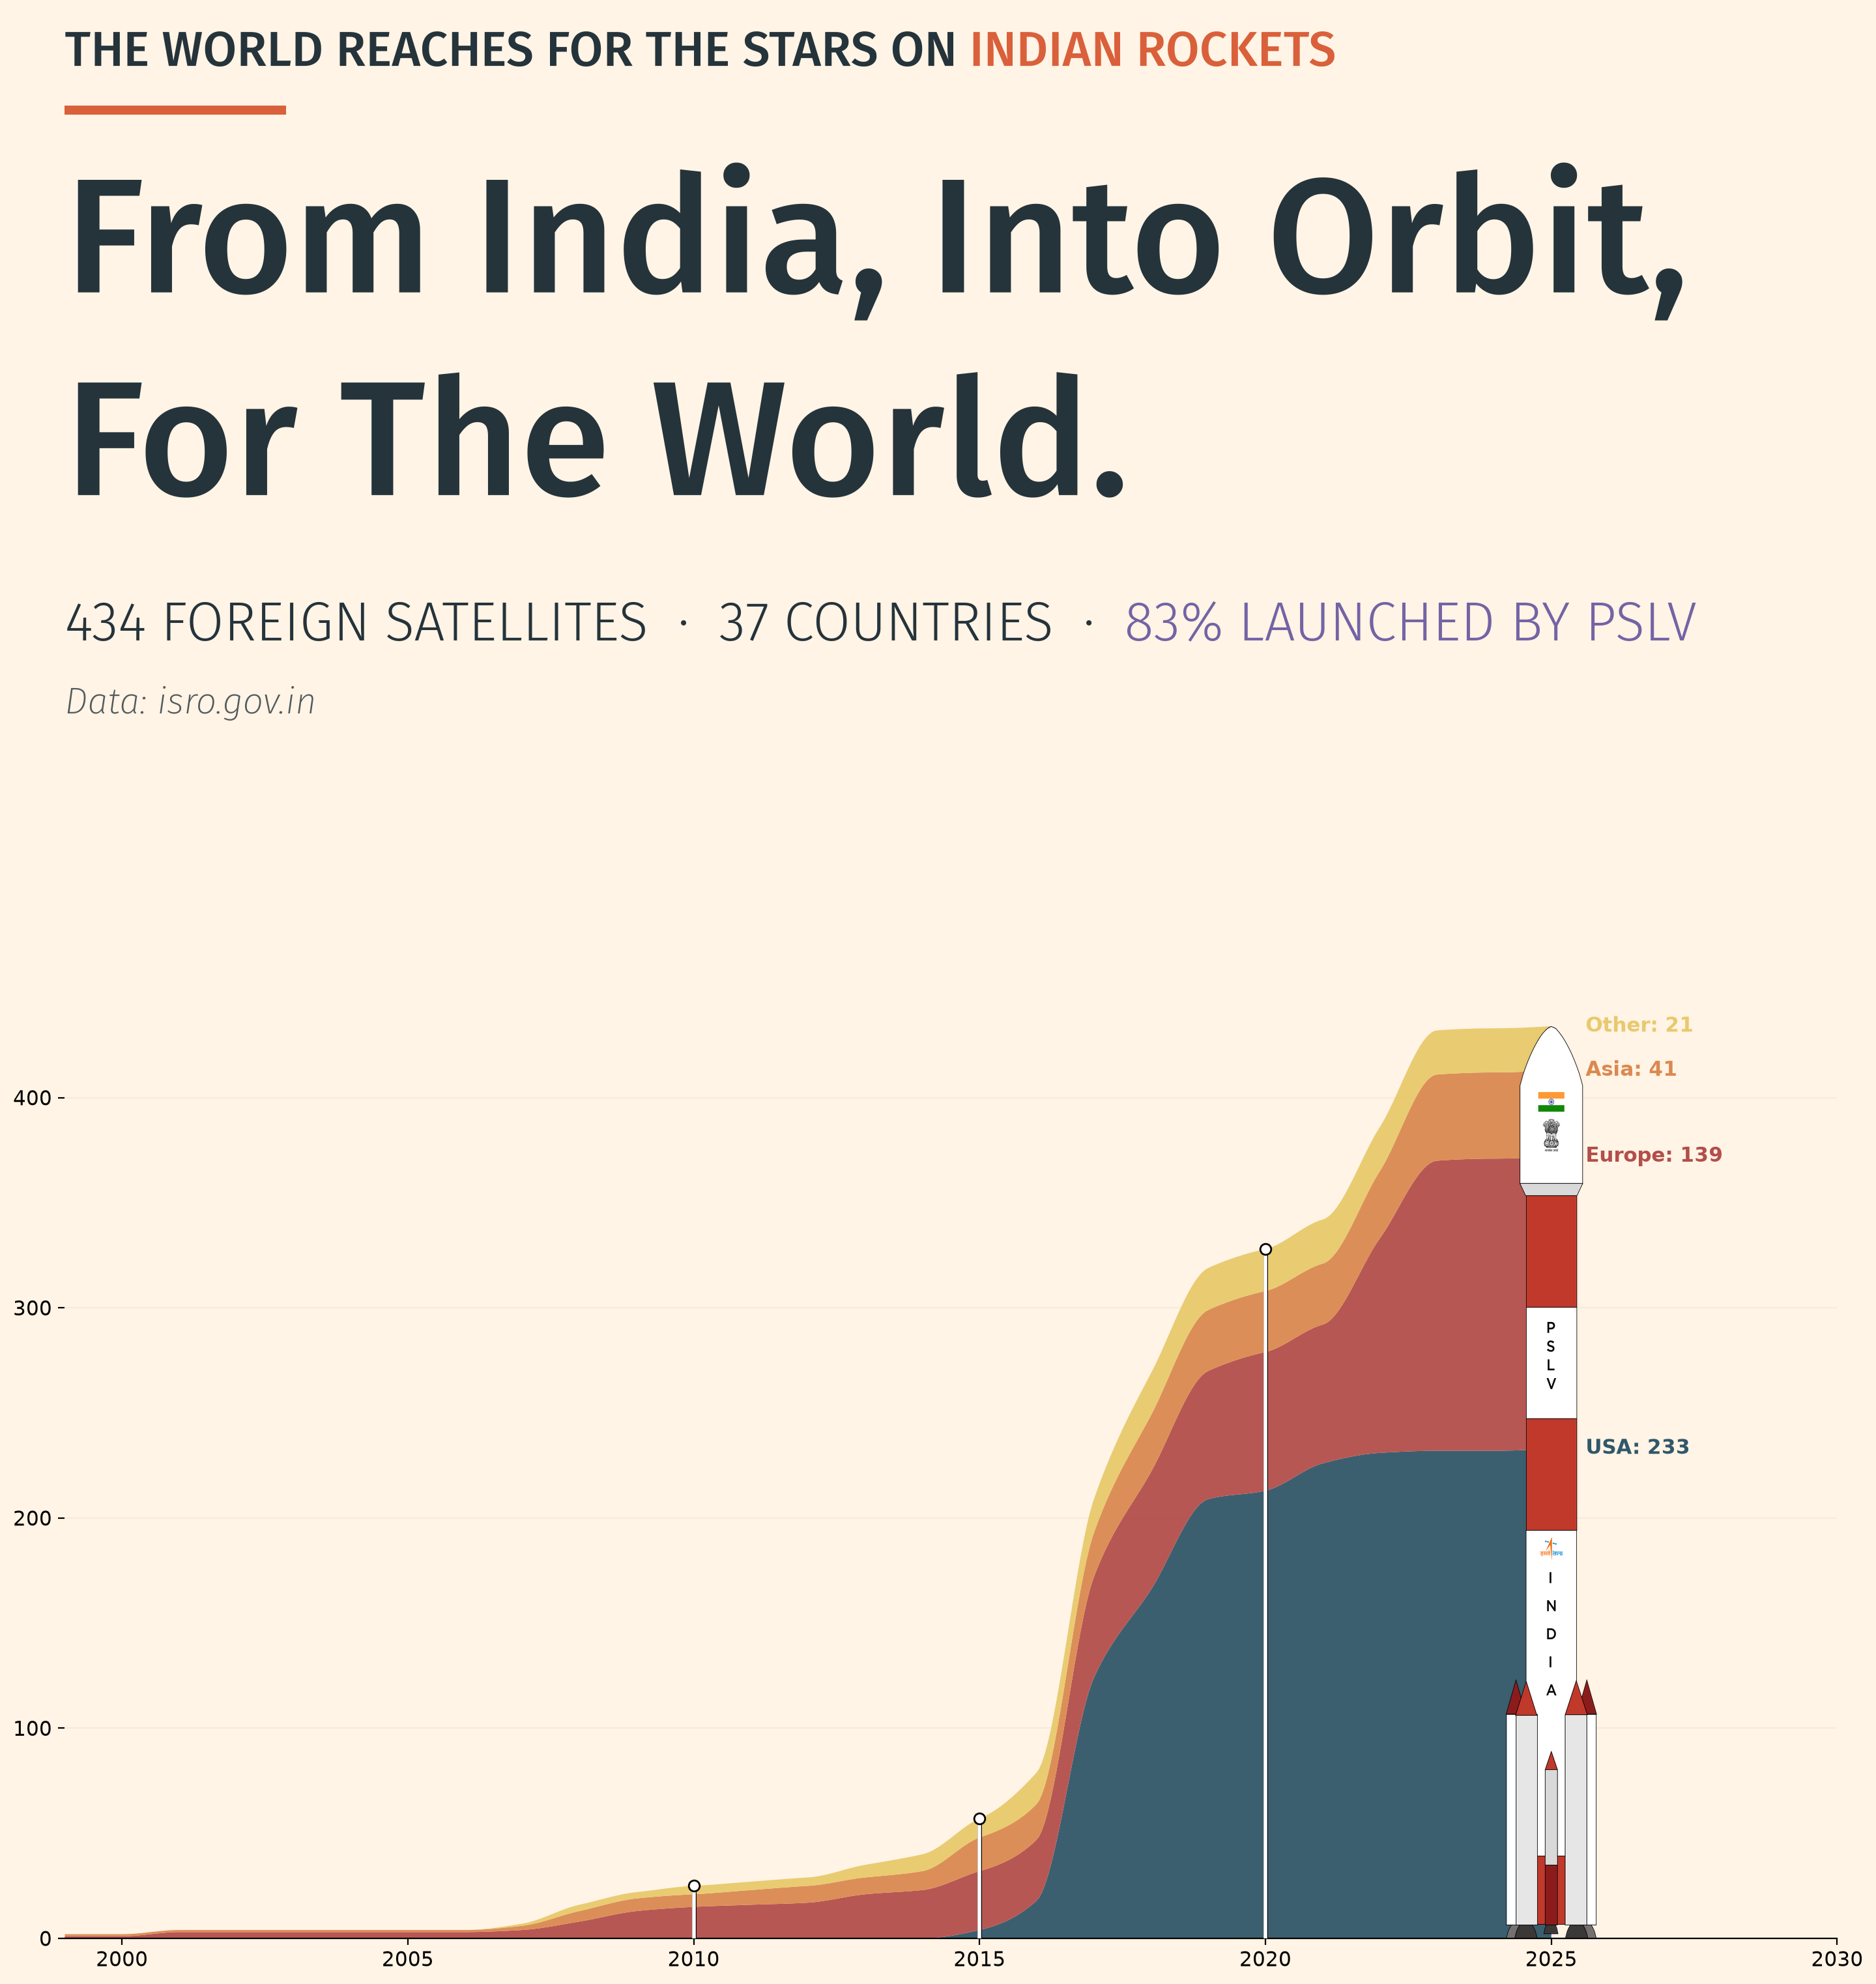

In [47]:
dpi = 200

fig, ax = plt.subplots(figsize=(17, 23), dpi=dpi)

fig.set_facecolor(color_palette["background"])
ax.set_facecolor(color_palette["background"])

fig.subplots_adjust(left=0.1, right=0.9, top=0.7, bottom=0.35)

# Title & Subtitles
# title
fig_text(
  x=0.1,
  y=0.99,
  s="THE WORLD REACHES FOR THE STARS ON <INDIAN ROCKETS>",
  size=27, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      dict(color=color_palette["accent"])
  ],
)

# short decorative underline
header_line = Line2D(
    [0.10, 0.2],
    [0.96, 0.96],
    color=color_palette["accent"],
    lw=5,
    solid_capstyle="butt",
    transform=fig.transFigure
)
fig.add_artist(header_line)

# Sub-title
fig_text(
  x=0.1,
  y=0.95,
  s="From India, Into Orbit,\nFor The World.",
  size=90, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      
  ],
)

# explanation
fig_text(
  x=0.1,
  y=0.8,
  s="434 FOREIGN SATELLITES  ·  37 COUNTRIES  ·  <83% LAUNCHED BY PSLV>",
  size=30, color=color_palette["text"],
  font=regular,
  highlight_textprops=[
      dict(color=color_palette["pslv"])
  ],
)

# data source
fig_text(
  x=0.1,
  y=0.77,
  s="Data: isro.gov.in",
  size=20,
  font=thin_italic,
  color=color_palette["text"],
  alpha=0.8
)

###################################

ax.stackplot(
    x_sm,
    y_usa_sm,
    y_eu_sm,
    y_asia_sm,
    y_other_sm,
    labels=region_cols,
    colors=region_colors,
    alpha=0.95
)

final_values = np.array([
    y_usa[-1],
    y_eu[-1],
    y_asia[-1],
    y_other[-1]
])

cumulative_values = np.cumsum(final_values)

bottom_values = np.concatenate((
    [0],
    cumulative_values[:-1]
))

end_values = np.cumsum(final_values)

for region, color, end, value in zip(
    region_cols,
    region_colors,
    end_values,
    final_values
):

    ax.text(
        x.max() + 0.6,
        end,
        f"{region}: {int(value):,}",
        fontsize=11,
        fontweight="bold",
        color=color,
        va="center"
    )


overall_total = int(final_values.sum())

ax.xaxis.set_major_locator(
    MultipleLocator(5)
)

ax.set_xlim(
    x.min(),
    x.max() + 5
)

ax.set_ylim(
    0,
    overall_total * 1.15
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="both",
    labelsize=11
)


##################################################
# PSLV images annotation                         #
##################################################

# Width of rocket in x-axis units (years)
rocket_width = {
    2010:0.2,
    2015:0.3,
    2020:1.2,
    2025:1.6
}

# Preserve existing axis limits
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

# Draw rockets at milestone years
y_min, y_max = ax.get_ylim()
for year, total in zip(milestone_years, milestone_totals):
    if year == 2025:
        ax.imshow(
            rocket_img,
            extent=[
                year - rocket_width.get(year, 2) / 2,
                year + rocket_width.get(year, 2) / 2,
                0,
                total
            ],
            aspect="auto",
            interpolation="lanczos",
            zorder=4
        )
    else:
        ymax_axes = (total - y_min) / (y_max - y_min)
        ax.axvline(x=year, ymax=ymax_axes, color="black", linewidth=2.5, zorder=2)
        ax.axvline(x=year, ymax=ymax_axes, color="white", linewidth=2, zorder=5)
        ax.scatter(x=[year], y=[total], marker="o", facecolor="white", edgecolor="black", zorder=10)

# Restore axis limits
ax.set_xlim(x_limits)
ax.set_ylim(y_limits)


save_path = os.path.join(
    "..", "viz",
    "test_sm_pslv.jpeg"
)

plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=1)